# Lab 3.2 · CUDA kernel selection

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

A runtime dispatches a kernel based on device capability, input dtype, shape, and other constraints such as alignment or layout. The fastest candidate that fails a constraint is unusable for that request. First filter for compatibility and output parity, then choose with measurements for the matching workload.

The fixture below represents fictional benchmark results at two GEMM row counts. The fast implementation requires a recent device, BF16, and an aligned input width. The baseline supports every configuration in the exercise. Use the small batch and large batch measurements independently. Real runtimes may autotune or cache a dispatch plan.

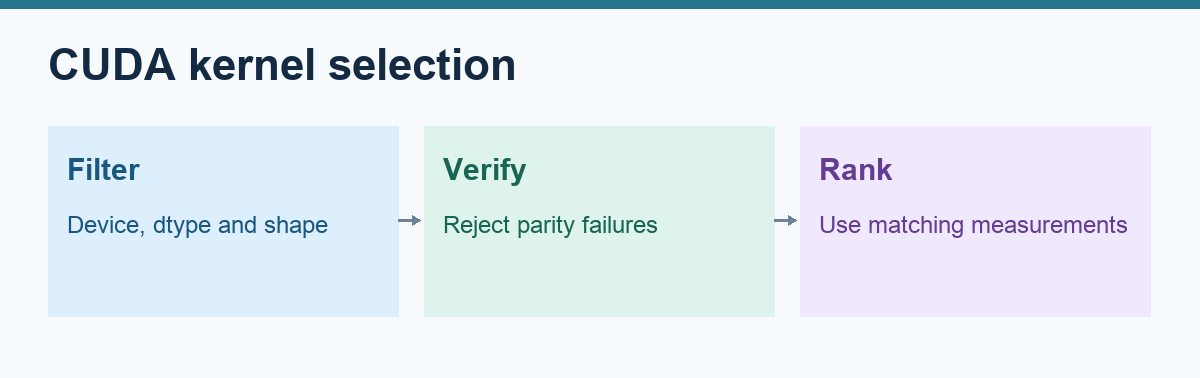

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Filter candidates | Return the names of compatible kernels with passing parity, in fixture order. A dtype of None accepts any dtype. | Alignment, device generation and parity can each remove a faster candidate. |
| 2. Select by shape | Find the eligible kernel with the lowest measured time for the specified row count. Return None if there is no measurement for any eligible kernel. | A winner at batch one can lose for a larger operation. Record dtype, layout, shape, hardware, and measurement method with a dispatch decision. |

In [ ]:
kernels = [
    {"name": "baseline", "min_device": 80, "dtype": None, "alignment": 1, "parity": True,
     "time": {1: 9, 128: 90}},
    {"name": "tiled", "min_device": 90, "dtype": "bf16", "alignment": 16, "parity": True,
     "time": {1: 12, 128: 40}},
    {"name": "experimental", "min_device": 90, "dtype": "bf16", "alignment": 16, "parity": False,
     "time": {1: 4, 128: 22}},
]

## Exercise 1. Filter candidates

Return the names of compatible kernels with passing parity, in fixture order. A dtype of None accepts any dtype.

In [ ]:
def eligible(device, dtype, width):
    return None

In [ ]:
result = eligible(90, "bf16", 128)
if result is None:
    print("Complete eligible.")
else:
    assert result == ["baseline", "tiled"]
    assert eligible(80, "bf16", 128) == eligible(90, "fp32", 128) == eligible(90, "bf16", 130) == ["baseline"]
    print("PASS — viable candidates:", result)

### Read the result

Alignment, device generation and parity can each remove a faster candidate.

## Exercise 2. Select by shape

Find the eligible kernel with the lowest measured time for the specified row count. Return None if there is no measurement for any eligible kernel.

In [ ]:
def select(device, dtype, width, rows):
    return None

In [ ]:
if result is not None:
    small, large = [select(90, "bf16", 128, n) for n in (1, 128)]
    if small is not None and large is not None:
        assert (small, large) == ("baseline", "tiled")
        assert select(80, "bf16", 128, 128) == "baseline"
        assert select(90, "bf16", 128, 32) is None
        print("PASS — winner changes with row count:", small, large)

### Read the result

A winner at batch one can lose for a larger operation. Record dtype, layout, shape, hardware, and measurement method with a dispatch decision.

## Optional extension

Add a new shape to the measurements and explain when you would re-run autotuning after a runtime or GPU change.

## Reading

Philip Kiely, *Inference Engineering*, §4.1.2, pp. 98–99.

- [NVIDIA CUDA programming guide](https://docs.nvidia.com/cuda/cuda-programming-guide/02-basics/writing-cuda-kernels.html)